In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [32]:

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load Dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=10000
)

# Padding
max_length = 200

X_train = pad_sequences(
    X_train, maxlen=max_length, padding="post", truncating="post"
)

X_test = pad_sequences(
    X_test, maxlen=max_length, padding="post", truncating="post"
)

print(X_train.shape)
print(X_test.shape)

(25000, 200)
(25000, 200)


## 1. Neural Networks for NLP

Understanding how Neural Networks process and learn from natural language data, including text representation, feature extraction, and language modeling.

**Key Concepts:** <span style="color:green">Neural Networks, Embedding, Text Representation, Language Modeling</span>

---

<div align="center">
    <img src="images/Mlp.svg" alt="MLP Architecture" width="100%">
</div>

In [33]:

model = Sequential([
    layers.Input(shape=(200,)),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [34]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │        25,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,257 (297.88 KB)

 Trainable params: 76,257 (297.88 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5011 - loss: 5.4541 - val_accuracy: 0.4938 - val_loss: 0.6933
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5006 - loss: 0.7812 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4992 - loss: 0.7162 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4995 - loss: 0.7326 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5002 - loss: 0.6963 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.4995 - loss: 0.6976 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4999 - loss: 0.6936 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5001 - loss: 0.7020 - val_accuracy: 0.

In [36]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5000 - loss: 0.6932
Test Loss: 0.6931570172309875
Test Accuracy: 0.5


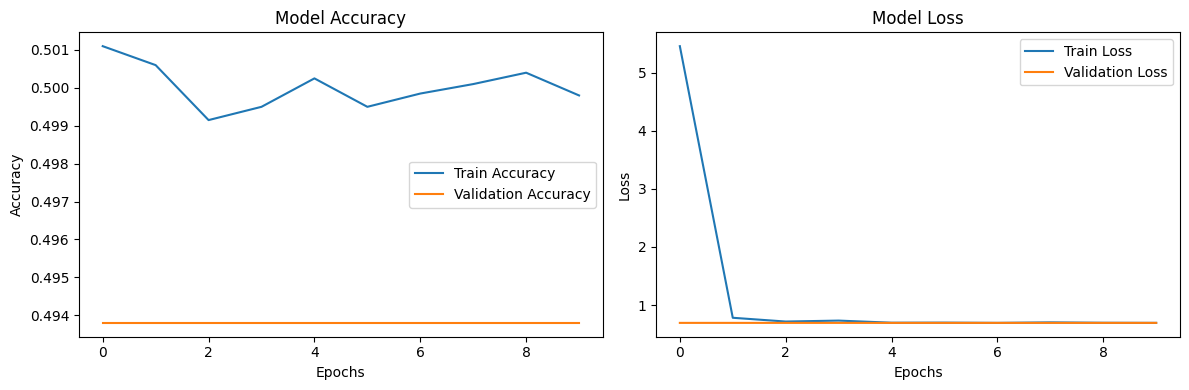

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 2. Recurrent Neural Networks (RNN)

Learning how RNNs process sequential data by maintaining information from previous time steps through recurrent connections.

**Key Concepts:** <span style="color:green">RNN, Hidden State, Sequential Data, Recurrent Connections</span>

---

<div align="center">
    <img src="images/Rnn.svg" alt="RNN Architecture" width="100%">
</div>

In [38]:


model = Sequential([
    layers.Input(shape=(200,)),

    layers.Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    layers.SimpleRNN(128),

    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [39]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,785 (2.54 MB)

 Trainable params: 666,785 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.4989 - loss: 0.6967 - val_accuracy: 0.4992 - val_loss: 0.6932
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4938 - loss: 0.6935 - val_accuracy: 0.5012 - val_loss: 0.6931
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4960 - loss: 0.6932 - val_accuracy: 0.5054 - val_loss: 0.6931
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4992 - loss: 0.6933 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.4992 - loss: 0.6933 - val_accuracy: 0.4938 - val_loss: 0.6932
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step - accuracy: 0.5381 - loss: 0.6870 - val_accuracy: 0.6092 - val_loss: 0.6719
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 20ms/step - accuracy: 0.6898 - loss: 0.5864 - val_accuracy: 0.6486 - val_loss: 0.6289
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.6880 - loss: 0.5836 - 

In [41]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6016 - loss: 0.6592
Test Loss: 0.6591993570327759
Test Accuracy: 0.6015599966049194


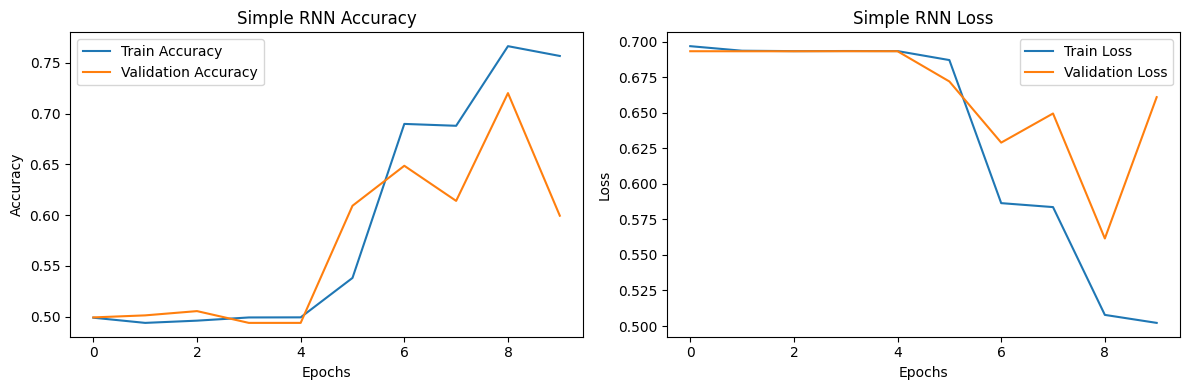

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Simple RNN Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Simple RNN Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 3. Long Short-Term Memory (LSTM)

Understanding how LSTM networks solve the vanishing gradient problem and capture long-term dependencies using memory cells and gates.

**Key Concepts:** <span style="color:green">Memory Cell, Forget Gate, Input Gate, Output Gate, Cell State</span>

---

<div align="center">
    <img src="images/lstm.svg" alt="LSTM Architecture" width="100%">
</div>

In [43]:
model = Sequential([
    layers.Input(shape=(200,)),

    layers.Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    layers.LSTM(64),

    layers.Dropout(0.3),

    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

In [44]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 674,353 (2.57 MB)

 Trainable params: 674,353 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.6180 - loss: 0.6505 - val_accuracy: 0.5422 - val_loss: 0.6902
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.7308 - loss: 0.5383 - val_accuracy: 0.7938 - val_loss: 0.4463
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.8637 - loss: 0.3448 - val_accuracy: 0.8458 - val_loss: 0.3649
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9069 - loss: 0.2578 - val_accuracy: 0.8176 - val_loss: 0.4995
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9255 - loss: 0.2129 - val_accuracy: 0.8344 - val_loss: 0.4661
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8979 - loss: 0.2609 - val_accuracy: 0.8344 - val_loss: 0.4281
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9235 - loss: 0.2056 - val_accuracy: 0.8540 - val_loss: 0.4850
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9548 - loss: 0.1344 - val

In [46]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8227 - loss: 0.6764
Test Loss: 0.6763976812362671
Test Accuracy: 0.8226799964904785


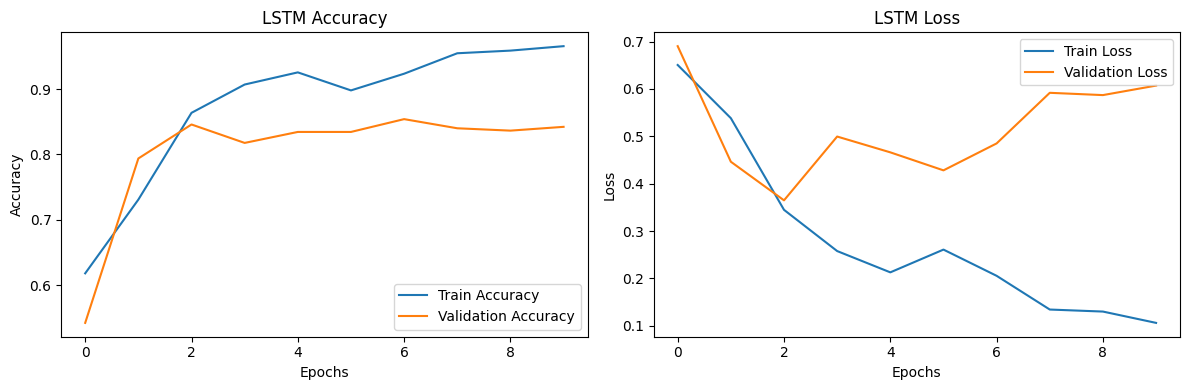

In [47]:


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 4. Gated Recurrent Units (GRU)

Exploring a simplified version of LSTM that uses two gates to control information flow and capture sequential dependencies.

**Key Concepts:** <span style="color:green">Update Gate, Reset Gate, Hidden State</span>

---

<div align="center">
    <img src="C:/Users/RTX/Desktop/gru.svg"
         alt="GRU Architecture"
         width="100%">
</div>

In [48]:

model = Sequential([
    layers.Input(shape=(200,)),
    layers.Embedding(input_dim=10000, output_dim=64, mask_zero=True),
    layers.GRU(64),
    layers.Dropout(0.4),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [49]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 666,017 (2.54 MB)

 Trainable params: 666,017 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

test_loss, test_acc = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.7002 - loss: 0.5654 - val_accuracy: 0.8342 - val_loss: 0.3965
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8701 - loss: 0.3279 - val_accuracy: 0.8546 - val_loss: 0.3596
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9121 - loss: 0.2448 - val_accuracy: 0.8738 - val_loss: 0.3373
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9373 - loss: 0.1805 - val_accuracy: 0.8618 - val_loss: 0.3778
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9568 - loss: 0.1321 - val_accuracy: 0.8728 - val_loss: 0.4156
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9690 - loss: 0.0935 - val_accuracy: 0.8674 - val_loss: 0.5106
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9830 - loss: 0.0542 - val_accuracy: 0.8612 - val_loss: 0.5736
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9901 - loss: 0.0341 - val_ac

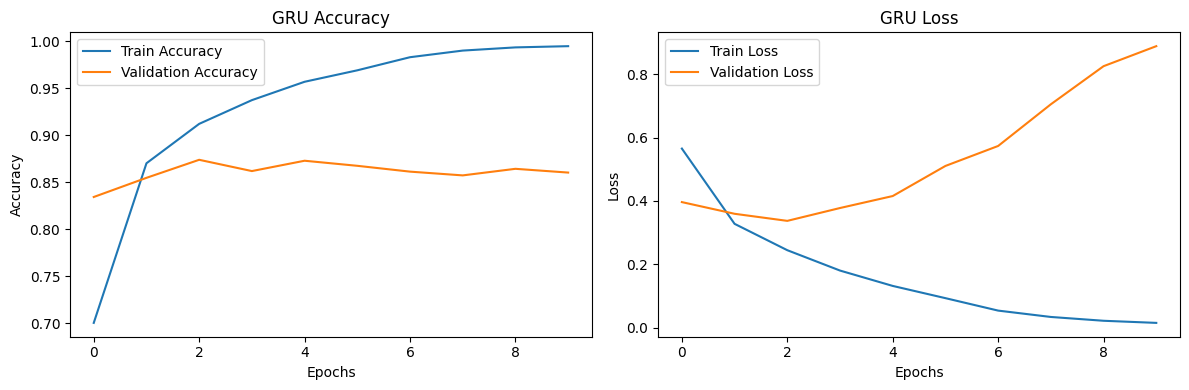

In [51]:


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("GRU Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("GRU Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 5. Bidirectional LSTM (BiLSTM)

Understanding how Bidirectional LSTM processes sequences in both forward and backward directions, capturing information from both previous and future contexts at each time step.

**Key Concepts:** <span style="color:green">BiLSTM, Forward LSTM, Backward LSTM, Concatenation, Contextual Information, Bidirectional Processing</span>

<div align="center">
    <img src="C:\Users\RTX\Desktop\bilstm.svg"
         alt="Bidirectional LSTM Architecture"
         width="100%">
</div>

In [51]:
model = Sequential([
    layers.Input(shape=(200,)),

    layers.Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    layers.Bidirectional(
        layers.LSTM(64)
    ),

    layers.Dropout(0.2),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [51]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

In [52]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9959 - loss: 0.0118 - val_accuracy: 0.8602 - val_loss: 0.9450
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9988 - loss: 0.0038 - val_accuracy: 0.8604 - val_loss: 1.0077
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9993 - loss: 0.0023 - val_accuracy: 0.8638 - val_loss: 1.0664
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9997 - loss: 0.0010 - val_accuracy: 0.8608 - val_loss: 1.1860
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 1.0000 - loss: 2.6587e-04 - val_accuracy: 0.8588 - val_loss: 1.2560


In [53]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8302 - loss: 1.5274
Test Loss: 1.5273576974868774
Test Accuracy: 0.83024001121521


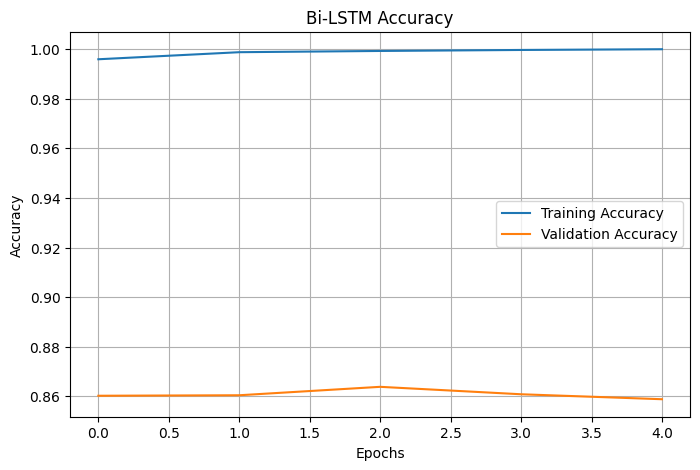

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Bi-LSTM Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

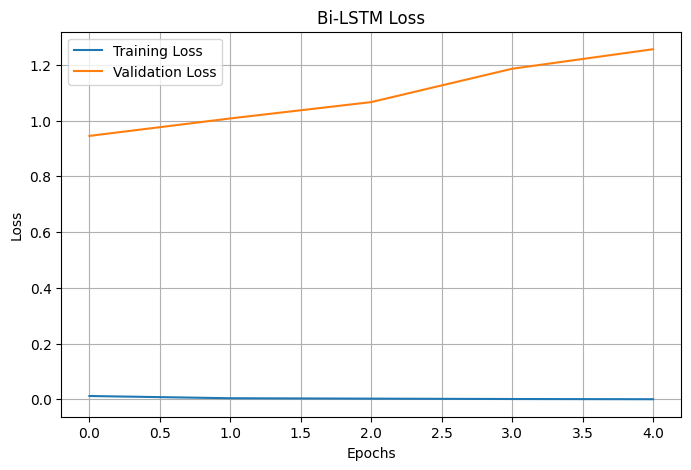

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Bi-LSTM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

## 6. Sequence-to-Sequence (Seq2Seq)

Learning how Encoder-Decoder architectures transform input sequences into output sequences, especially in machine translation and text generation.

**Key Concepts:** <span style="color:green">Encoder, Decoder, Context Vector, Teacher Forcing, Sequence Generation</span>

---


<div align="center">
    <img src="C:/Users/RTX/Desktop/seq2seq.svg"
         alt="Sequence to Sequence Architecture"
         width="100%">
</div>

In [59]:
import numpy as np
import keras
from keras import layers
import requests
import zipfile
import os

In [60]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip"

response = requests.get(url)
response.raise_for_status()

with open("fra-eng.zip", "wb") as f:
    f.write(response.content)

with zipfile.ZipFile("fra-eng.zip", "r") as z:
    z.extractall("fra_data")

data_path = "fra_data/fra.txt"

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [61]:
batch_size = 64
epochs = 20
latent_dim = 128
num_samples = 10000

In [62]:
input_texts = []
target_texts = []

input_characters = set()
target_characters = set()

with open(data_path, encoding="utf-8") as f:
    lines = f.read().split("\n")

for line in lines[:num_samples]:

    parts = line.split("\t")

    if len(parts) < 2:
        continue

    input_text = parts[0]
    target_text = "\t" + parts[1] + "\n"

    input_texts.append(input_text)
    target_texts.append(target_text)

    input_characters.update(input_text)
    target_characters.update(target_text)

In [63]:
input_characters = sorted(list(input_characters))
target_characters = sorted(list(target_characters))

num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)

max_encoder_seq_length = max(
    len(txt) for txt in input_texts
)

max_decoder_seq_length = max(
    len(txt) for txt in target_texts
)

input_token_index = {
    char: i for i, char in enumerate(input_characters)
}

target_token_index = {
    char: i for i, char in enumerate(target_characters)
}

print("Number of samples:", len(input_texts))
print("Encoder Tokens:", num_encoder_tokens)
print("Decoder Tokens:", num_decoder_tokens)
print("Max Encoder Length:", max_encoder_seq_length)
print("Max Decoder Length:", max_decoder_seq_length)

Number of samples: 10000
Encoder Tokens: 70
Decoder Tokens: 93
Max Encoder Length: 16
Max Decoder Length: 59


In [64]:
encoder_input_data = np.zeros(
    (len(input_texts), max_encoder_seq_length, num_encoder_tokens),
    dtype="float32"
)

decoder_input_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens),
    dtype="float32"
)

decoder_target_data = np.zeros(
    (len(input_texts), max_decoder_seq_length, num_decoder_tokens),
    dtype="float32"
)

In [65]:
for i, (input_text, target_text) in enumerate(
    zip(input_texts, target_texts)
):

    for t, char in enumerate(input_text):
        encoder_input_data[i, t, input_token_index[char]] = 1.0

    encoder_input_data[
        i, t + 1:, input_token_index[" "]
    ] = 1.0

    for t, char in enumerate(target_text):

        decoder_input_data[
            i, t, target_token_index[char]
        ] = 1.0

        if t > 0:
            decoder_target_data[
                i, t - 1, target_token_index[char]
            ] = 1.0

    decoder_input_data[
        i, t + 1:, target_token_index[" "]
    ] = 1.0

    decoder_target_data[
        i, t:, target_token_index[" "]
    ] = 1.0

In [66]:
# Encoder
encoder_inputs = keras.Input(
    shape=(None, num_encoder_tokens)
)

encoder = layers.LSTM(
    latent_dim,
    return_state=True
)

_, state_h, state_c = encoder(encoder_inputs)

encoder_states = [state_h, state_c]


# Decoder
decoder_inputs = keras.Input(
    shape=(None, num_decoder_tokens)
)

decoder_lstm = layers.LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_inputs,
    initial_state=encoder_states
)


# Output
decoder_dense = layers.Dense(
    num_decoder_tokens,
    activation="softmax"
)

decoder_outputs = decoder_dense(decoder_outputs)


# Model
model = keras.Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_6       │ (None, None, 93)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 128),     │    101,888 │ input_layer_5[0]… │
│                     │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, None,     │    113,664 │ input_layer_6[0]… │
│                     │ 128), (None,      │            │ lstm_1[0][1],     │
│                     │ 128), (None,      │            │ lstm_1[0][2]      │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, None, 93)  │     11,997 │ lstm_2[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 227,549 (888.86 KB)

 Trainable params: 227,549 (888.86 KB)

 Non-trainable params: 0 (0.00 B)

In [67]:
model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [78]:
history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2
)

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.9077 - loss: 0.3100 - val_accuracy: 0.8680 - val_loss: 0.4659
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9077 - loss: 0.3089 - val_accuracy: 0.8676 - val_loss: 0.4663
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9086 - loss: 0.3069 - val_accuracy: 0.8678 - val_loss: 0.4668
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9091 - loss: 0.3053 - val_accuracy: 0.8676 - val_loss: 0.4665
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9095 - loss: 0.3038 - val_accuracy: 0.8684 - val_loss: 0.4653
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9099 - loss: 0.3022 - val_accuracy: 0.8677 - val_loss: 0.4665
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9105 - loss: 0.3007 - val_accuracy: 0.8682 - val_loss: 0.4665
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9111 - loss: 0.2990 - val_accu

In [79]:
model.save("seq2seq_model.keras")

In [80]:
encoder_model = keras.Model(
    encoder_inputs,
    encoder_states
)

In [81]:
decoder_state_input_h = keras.Input(
    shape=(latent_dim,)
)

decoder_state_input_c = keras.Input(
    shape=(latent_dim,)
)

decoder_states_inputs = [
    decoder_state_input_h,
    decoder_state_input_c
]

decoder_outputs, state_h_dec, state_c_dec = decoder_lstm(
    decoder_inputs,
    initial_state=decoder_states_inputs
)

decoder_states = [state_h_dec, state_c_dec]

decoder_outputs = decoder_dense(decoder_outputs)

decoder_model = keras.Model(
    [decoder_inputs] + decoder_states_inputs,
    [decoder_outputs] + decoder_states
)

In [82]:
reverse_target_char_index = {
    i: char for char, i in target_token_index.items()
}

In [83]:
def decode_sequence(input_seq):

    states_value = encoder_model.predict(
        input_seq,
        verbose=0
    )

    target_seq = np.zeros(
        (1, 1, num_decoder_tokens)
    )

    target_seq[0, 0, target_token_index["\t"]] = 1.0

    decoded_sentence = ""

    for _ in range(max_decoder_seq_length):

        output_tokens, h, c = decoder_model.predict(
            [target_seq] + states_value,
            verbose=0
        )

        sampled_index = np.argmax(
            output_tokens[0, -1, :]
        )

        sampled_char = reverse_target_char_index[sampled_index]

        if sampled_char == "\n":
            break

        decoded_sentence += sampled_char

        target_seq = np.zeros(
            (1, 1, num_decoder_tokens)
        )

        target_seq[0, 0, sampled_index] = 1.0

        states_value = [h, c]

    return decoded_sentence

In [84]:
for i in range(20):

    input_seq = encoder_input_data[i:i+1]

    decoded_sentence = decode_sequence(input_seq)

    print("Input:", input_texts[i])
    print("Actual:", target_texts[i][1:-1])
    print("Predicted:", decoded_sentence)

    print("-" * 40)

Input: Go.
Actual: Va !
Predicted: Va voir !
----------------------------------------
Input: Hi.
Actual: Salut !
Predicted: Collant !
----------------------------------------
Input: Run!
Actual: Cours !
Predicted: Prends un bouss !
----------------------------------------
Input: Run!
Actual: Courez !
Predicted: Prends un bouss !
----------------------------------------
Input: Who?
Actual: Qui ?
Predicted: Qui est allessée ?
----------------------------------------
Input: Wow!
Actual: Ça alors !
Predicted: Fait-ce avec moi.
----------------------------------------
Input: Fire!
Actual: Au feu !
Predicted: Prends-le l'aissoir !
----------------------------------------
Input: Help!
Actual: À l'aide !
Predicted: Assez-vous !
----------------------------------------
Input: Jump.
Actual: Saute.
Predicted: Regarde !
----------------------------------------
Input: Stop!
Actual: Ça suffit !
Predicted: Regarde !
----------------------------------------
Input: Stop!
Actual: Stop !
Predicted: Regar

## 7. Attention Mechanism

Understanding how Attention allows models to focus on the most relevant parts of the input sequence instead of relying only on a fixed-length context vector.

**Key Concepts:** <span style="color:green">Attention Scores, Query, Key, Value, Context Vector, Alignment</span>

---

In [106]:

# ==========================================
# 1. Encoder
# ==========================================

encoder_inputs = keras.Input(
    shape=(None, num_encoder_tokens)
)

encoder_lstm = layers.LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

encoder_outputs, state_h, state_c = encoder_lstm(
    encoder_inputs
)

encoder_states = [state_h, state_c]


# ==========================================
# 2. Decoder
# ==========================================

decoder_inputs = keras.Input(
    shape=(None, num_decoder_tokens)
)

decoder_lstm = layers.LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

decoder_outputs, _, _ = decoder_lstm(
    decoder_inputs,
    initial_state=encoder_states
)


# ==========================================
# 3. Attention Mechanism
# ==========================================

attention_layer = layers.AdditiveAttention(
    name="attention"
)

context_vector = attention_layer(
    [decoder_outputs, encoder_outputs]
)


# ==========================================
# 4. Combine Decoder + Context
# ==========================================

decoder_combined = layers.Concatenate(
    axis=-1
)([decoder_outputs, context_vector])


# ==========================================
# 5. Output Layer
# ==========================================

decoder_dense = layers.Dense(
    num_decoder_tokens,
    activation="softmax"
)

decoder_outputs = decoder_dense(
    decoder_combined
)


# ==========================================
# 6. Build Model
# ==========================================

model = keras.Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.summary()


Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, None, 70)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_14      │ (None, None, 93)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ [(None, None,     │    101,888 │ input_layer_13[0… │
│                     │ 128), (None,      │            │                   │
│                     │ 128), (None,      │            │                   │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_6 (LSTM)       │ [(None, None,     │    113,664 │ input_layer_14[0… │
│                     │ 128), (None,      │            │ lstm_5[0][1],     │
│                     │ 128), (None,      │            │ lstm_5[0][2]      │
│                     │ 128)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, None, 128) │        128 │ lstm_6[0][0],     │
│ (AdditiveAttention) │                   │            │ lstm_5[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, None, 256) │          0 │ lstm_6[0][0],     │
│ (Concatenate)       │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, None, 93)  │     23,901 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 239,581 (935.86 KB)

 Trainable params: 239,581 (935.86 KB)

 Non-trainable params: 0 (0.00 B)

In [110]:

model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    [encoder_input_data, decoder_input_data],
    decoder_target_data,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.2
)

model.save("seq2seq_attention_model.keras")


Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9062 - loss: 0.3144 - val_accuracy: 0.8646 - val_loss: 0.4712
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9072 - loss: 0.3111 - val_accuracy: 0.8648 - val_loss: 0.4709
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9079 - loss: 0.3088 - val_accuracy: 0.8650 - val_loss: 0.4709
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9086 - loss: 0.3068 - val_accuracy: 0.8643 - val_loss: 0.4724
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9094 - loss: 0.3046 - val_accuracy: 0.8648 - val_loss: 0.4707
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9097 - loss: 0.3027 - val_accuracy: 0.8648 - val_loss: 0.4724
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9104 - loss: 0.3006 - val_accuracy: 0.8651 - val_loss: 0.4718
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9111 - loss: 0.2985 - val_accu

In [111]:

# ==========================================
# 1. Encoder Inference Model
# ==========================================

encoder_model = keras.Model(
    encoder_inputs,
    [encoder_outputs, state_h, state_c]
)


# ==========================================
# 2. Decoder State Inputs
# ==========================================

decoder_state_input_h = keras.Input(
    shape=(latent_dim,)
)

decoder_state_input_c = keras.Input(
    shape=(latent_dim,)
)

decoder_states_inputs = [
    decoder_state_input_h,
    decoder_state_input_c
]


# ==========================================
# 3. Encoder Outputs Input
# ==========================================

encoder_outputs_input = keras.Input(
    shape=(None, latent_dim)
)


# ==========================================
# 4. Decoder One-Step
# ==========================================

decoder_outputs, state_h_dec, state_c_dec = decoder_lstm(
    decoder_inputs,
    initial_state=decoder_states_inputs
)

decoder_states = [
    state_h_dec,
    state_c_dec
]


# ==========================================
# 5. Attention
# ==========================================

context_vector, attention_weights = attention_layer(
    [decoder_outputs, encoder_outputs_input],
    return_attention_scores=True
)


# ==========================================
# 6. Combine
# ==========================================

decoder_combined = layers.Concatenate(
    axis=-1
)([decoder_outputs, context_vector])


# ==========================================
# 7. Output
# ==========================================

decoder_outputs = decoder_dense(
    decoder_combined
)


# ==========================================
# 8. Decoder Model
# ==========================================

decoder_model = keras.Model(
    [decoder_inputs]
    + decoder_states_inputs
    + [encoder_outputs_input],

    [decoder_outputs]
    + decoder_states
    + [attention_weights]
)


In [112]:

reverse_target_char_index = {
    i: char
    for char, i in target_token_index.items()
}


def decode_sequence(input_seq):

    # Get Encoder Outputs and States
    encoder_output, state_h, state_c = encoder_model.predict(
        input_seq,
        verbose=0
    )

    states_value = [state_h, state_c]

    # Start Token
    target_seq = np.zeros(
        (1, 1, num_decoder_tokens)
    )

    target_seq[0, 0, target_token_index["\t"]] = 1.0

    decoded_sentence = ""

    attention_history = []

    for _ in range(max_decoder_seq_length):

        # Decoder Prediction
        output_tokens, h, c, attention_weights = decoder_model.predict(
            [target_seq] + states_value + [encoder_output],
            verbose=0
        )

        # Get Predicted Character
        sampled_index = np.argmax(
            output_tokens[0, -1, :]
        )

        sampled_char = reverse_target_char_index[sampled_index]

        # Stop at End Token
        if sampled_char == "\n":
            break

        decoded_sentence += sampled_char

        # Save Attention Weights
        attention_history.append(
            attention_weights[0, 0, :]
        )

        # Next Decoder Input
        target_seq = np.zeros(
            (1, 1, num_decoder_tokens)
        )

        target_seq[0, 0, sampled_index] = 1.0

        # Update States
        states_value = [h, c]

    return decoded_sentence, np.array(attention_history)


In [113]:

for i in range(20):

    input_seq = encoder_input_data[i:i+1]

    predicted, attention_weights = decode_sequence(input_seq)

    print("Input:    ", input_texts[i])
    print("Actual:   ", target_texts[i][1:-1])
    print("Predicted:", predicted)

    print("-" * 40)


Input:     Go.
Actual:    Va !
Predicted: Allez-vous !
----------------------------------------
Input:     Hi.
Actual:    Salut !
Predicted: Comment est-il !
----------------------------------------
Input:     Run!
Actual:    Cours !
Predicted: Laisse-moi !
----------------------------------------
Input:     Run!
Actual:    Courez !
Predicted: Laisse-moi !
----------------------------------------
Input:     Who?
Actual:    Qui ?
Predicted: Qui est-il ?
----------------------------------------
Input:     Wow!
Actual:    Ça alors !
Predicted: Fait-ce que ça ?
----------------------------------------
Input:     Fire!
Actual:    Au feu !
Predicted: La vie !
----------------------------------------
Input:     Help!
Actual:    À l'aide !
Predicted: Lar !
----------------------------------------
Input:     Jump.
Actual:    Saute.
Predicted: Laisse-toi !
----------------------------------------
Input:     Stop!
Actual:    Ça suffit !
Predicted: Attends-nous !
----------------------------------

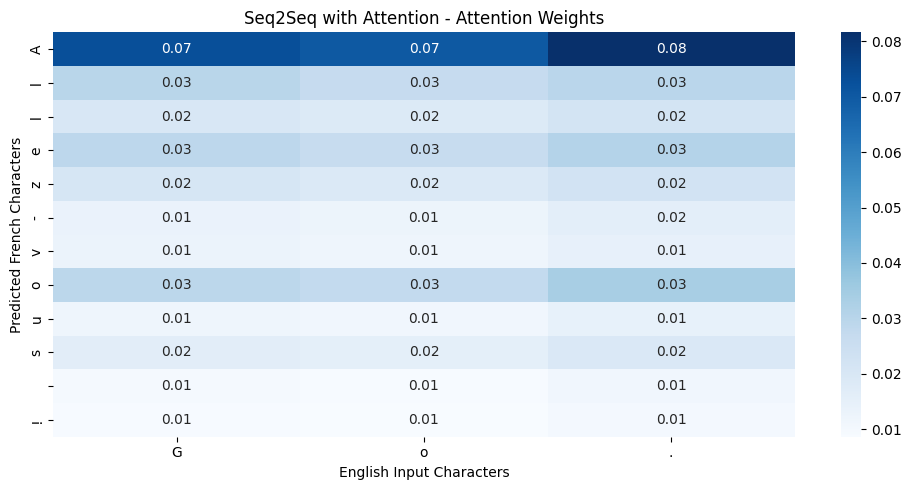

Input:     Go.
Predicted: Allez-vous !


In [114]:

import matplotlib.pyplot as plt
import seaborn as sns

# Choose one example
i = 0

input_seq = encoder_input_data[i:i+1]

predicted, attention_weights = decode_sequence(input_seq)

# Characters
source_chars = list(input_texts[i])
target_chars = list(predicted)

# Plot
plt.figure(figsize=(10, 5))

sns.heatmap(
    attention_weights[:, :len(source_chars)],
    xticklabels=source_chars,
    yticklabels=target_chars,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)

plt.xlabel("English Input Characters")
plt.ylabel("Predicted French Characters")

plt.title("Seq2Seq with Attention - Attention Weights")

plt.tight_layout()
plt.show()

print("Input:    ", input_texts[i])
print("Predicted:", predicted)


## 8. Transformer from Scratch (TensorFlow / Keras)

Building a complete Encoder-Decoder Transformer architecture from scratch using TensorFlow and Keras for English-to-French machine translation.

**Key Concepts:** <span style="color:green">Transformer Architecture, Encoder, Decoder, Tokenization, Token Embeddings, Positional Embeddings, Multi-Head Attention, Self-Attention, Masked Self-Attention, Cross-Attention, Feed-Forward Network, Padding Mask, Causal Mask, Teacher Forcing, Training, Validation, Greedy Decoding</span>

---

In [115]:
# Prepare English and French sentences

english_sentences = input_texts

french_sentences = [
    text[1:-1].lower()
    for text in target_texts
]

# Add Start and End Tokens

target_sentences = [
    "startseq " + text + " endseq"
    for text in french_sentences
]

# Calculate maximum lengths

max_encoder_length = max(
    len(text.split())
    for text in english_sentences
)

max_decoder_length = max(
    len(text.split())
    for text in target_sentences
)

print("Number of samples:", len(english_sentences))
print("Max English Length:", max_encoder_length)
print("Max French Length:", max_decoder_length)

Number of samples: 10000
Max English Length: 5
Max French Length: 12


In [116]:
# English Tokenizer

english_vectorizer = layers.TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=max_encoder_length
)

english_vectorizer.adapt(english_sentences)


# French Tokenizer

french_vectorizer = layers.TextVectorization(
    max_tokens=10000,
    output_mode="int",
    output_sequence_length=max_decoder_length
)

french_vectorizer.adapt(target_sentences)


# Vocabulary Sizes

english_vocab_size = len(
    english_vectorizer.get_vocabulary()
)

french_vocab_size = len(
    french_vectorizer.get_vocabulary()
)

print("English Vocabulary:", english_vocab_size)
print("French Vocabulary:", french_vocab_size)

English Vocabulary: 2138
French Vocabulary: 4845


In [118]:
# Convert sentences to token IDs

encoder_data = english_vectorizer(
    english_sentences
)

decoder_full = french_vectorizer(
    target_sentences
)

# Teacher Forcing

decoder_input_data = decoder_full[:, :-1]

decoder_target_data = decoder_full[:, 1:]

# Ignore Padding Tokens in the loss

sample_weights = tf.cast(
    tf.not_equal(decoder_target_data, 0),
    tf.float32
)

print("Encoder Shape:", encoder_data.shape)
print("Decoder Input Shape:", decoder_input_data.shape)
print("Decoder Target Shape:", decoder_target_data.shape)
print("Sample Weights Shape:", sample_weights.shape)

Encoder Shape: (10000, 5)
Decoder Input Shape: (10000, 11)
Decoder Target Shape: (10000, 11)
Sample Weights Shape: (10000, 11)


In [119]:
class PositionalEmbedding(layers.Layer):

    def __init__(self, vocab_size, sequence_length, embed_dim):
        super().__init__()

        self.token_embedding = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            mask_zero=True
        )

        self.position_embedding = layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim
        )

    def call(self, inputs):

        length = keras.ops.shape(inputs)[-1]

        positions = keras.ops.arange(
            start=0,
            stop=length,
            step=1
        )

        token_vectors = self.token_embedding(inputs)

        position_vectors = self.position_embedding(positions)

        return token_vectors + position_vectors

In [120]:
class TransformerEncoder(layers.Layer):

    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.feed_forward = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)

    def call(self, inputs):

        x, padding_mask = inputs

        attention_mask = keras.ops.expand_dims(
            padding_mask, axis=1
        )

        attention_output = self.attention(
            query=x,
            value=x,
            key=x,
            attention_mask=attention_mask
        )

        x = self.norm1(
            x + self.dropout1(attention_output)
        )

        ff_output = self.feed_forward(x)

        x = self.norm2(
            x + self.dropout2(ff_output)
        )

        return x

In [121]:
class TransformerDecoder(layers.Layer):

    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()

        self.self_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.cross_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.feed_forward = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization()
        self.norm2 = layers.LayerNormalization()
        self.norm3 = layers.LayerNormalization()

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)
        self.dropout3 = layers.Dropout(dropout)

    def call(self, inputs):

        x, encoder_output, decoder_mask, encoder_mask = inputs

        # Masked Self-Attention

        decoder_attention_mask = keras.ops.expand_dims(
            decoder_mask, axis=1
        )

        attention_output = self.self_attention(
            query=x,
            value=x,
            key=x,
            attention_mask=decoder_attention_mask,
            use_causal_mask=True
        )

        x = self.norm1(
            x + self.dropout1(attention_output)
        )

        # Cross-Attention

        encoder_attention_mask = keras.ops.expand_dims(
            encoder_mask, axis=1
        )

        cross_output = self.cross_attention(
            query=x,
            value=encoder_output,
            key=encoder_output,
            attention_mask=encoder_attention_mask
        )

        x = self.norm2(
            x + self.dropout2(cross_output)
        )

        # Feed Forward

        ff_output = self.feed_forward(x)

        x = self.norm3(
            x + self.dropout3(ff_output)
        )

        return x

In [122]:
# Model Parameters

embed_dim = 128
num_heads = 4
ff_dim = 256


# Encoder Input

encoder_inputs = keras.Input(
    shape=(max_encoder_length,),
    dtype="int64"
)

# Decoder Input

decoder_inputs = keras.Input(
    shape=(max_decoder_length - 1,),
    dtype="int64"
)


# Padding Masks

encoder_mask = keras.ops.not_equal(
    encoder_inputs, 0
)

decoder_mask = keras.ops.not_equal(
    decoder_inputs, 0
)


# Encoder Embedding

encoder_embedding = PositionalEmbedding(
    english_vocab_size,
    max_encoder_length,
    embed_dim
)(encoder_inputs)


# Encoder

encoder_output = TransformerEncoder(
    embed_dim,
    num_heads,
    ff_dim
)([encoder_embedding, encoder_mask])


# Decoder Embedding

decoder_embedding = PositionalEmbedding(
    french_vocab_size,
    max_decoder_length - 1,
    embed_dim
)(decoder_inputs)


# Decoder

decoder_output = TransformerDecoder(
    embed_dim,
    num_heads,
    ff_dim
)([
    decoder_embedding,
    encoder_output,
    decoder_mask,
    encoder_mask
])


# Output Layer

outputs = layers.Dense(
    french_vocab_size
)(decoder_output)


# Build Model

transformer = keras.Model(
    [encoder_inputs, decoder_inputs],
    outputs
)

transformer.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_18      │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_19      │ (None, 11)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 5, 128)    │    274,304 │ input_layer_18[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 5)         │          0 │ input_layer_18[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 11, 128)   │    621,568 │ input_layer_19[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encoder │ (None, 5, 128)    │    132,480 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_5         │ (None, 11)        │          0 │ input_layer_19[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decoder │ (None, 11, 128)   │    198,784 │ positional_embed… │
│ (TransformerDecode… │                   │            │ transformer_enco… │
│                     │                   │            │ not_equal_5[0][0… │
│                     │                   │            │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 11, 4845)  │    625,005 │ transformer_deco… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,852,141 (7.07 MB)

 Trainable params: 1,852,141 (7.07 MB)

 Non-trainable params: 0 (0.00 B)

In [123]:
transformer.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),

    weighted_metrics=[
        "sparse_categorical_accuracy"
    ]
)


history = transformer.fit(
    [encoder_data, decoder_input_data],
    decoder_target_data,

    sample_weight=sample_weights,

    batch_size=64,
    epochs=20,
    validation_split=0.2
)

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 31s 76ms/step - loss: 1.8775 - sparse_categorical_accuracy: 0.3487 - val_loss: 1.6951 - val_sparse_categorical_accuracy: 0.4233
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - loss: 1.1979 - sparse_categorical_accuracy: 0.4968 - val_loss: 1.4638 - val_sparse_categorical_accuracy: 0.4823
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.9019 - sparse_categorical_accuracy: 0.5731 - val_loss: 1.3685 - val_sparse_categorical_accuracy: 0.5101
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.6918 - sparse_categorical_accuracy: 0.6433 - val_loss: 1.2982 - val_sparse_categorical_accuracy: 0.5344
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.5339 - sparse_categorical_accuracy: 0.7013 - val_loss: 1.2793 - val_sparse_categorical_accuracy: 0.5422
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.4159 - sparse_categorical_accuracy: 0.7450 - val_loss: 1.2925 - val_sparse_categorical_accuracy: 0.55

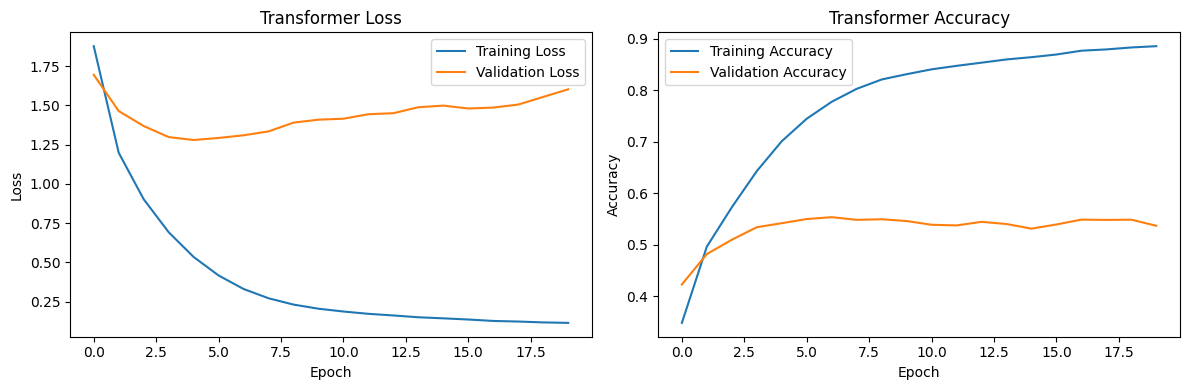

In [124]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Transformer Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history["sparse_categorical_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_sparse_categorical_accuracy"],
    label="Validation Accuracy"
)

plt.title("Transformer Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [125]:
# Get French Vocabulary

french_vocabulary = french_vectorizer.get_vocabulary()

start_id = french_vocabulary.index("startseq")
end_id = french_vocabulary.index("endseq")


def translate(sentence):

    # Encode English sentence

    encoder_input = english_vectorizer(
        [sentence]
    )

    # Start Token

    generated_tokens = [start_id]

    for _ in range(max_decoder_length - 1):

        decoder_input = np.zeros(
            (1, max_decoder_length - 1),
            dtype="int64"
        )

        decoder_input[0, :len(generated_tokens)] = generated_tokens

        # Predict Next Token

        predictions = transformer.predict(
            [encoder_input, decoder_input],
            verbose=0
        )

        next_token_logits = predictions[
            0, len(generated_tokens) - 1, :
        ]

        next_token_id = int(
            np.argmax(next_token_logits)
        )

        # Stop at End Token

        if next_token_id == end_id:
            break

        generated_tokens.append(next_token_id)

    # Convert IDs to Words

    translated_words = [
        french_vocabulary[token_id]
        for token_id in generated_tokens[1:]
    ]

    return " ".join(translated_words)

In [126]:
sentences = [
    "I love you",
    "How are you",
    "Good morning",
    "I am happy",
    "Thank you"
]

for sentence in sentences:

    prediction = translate(sentence)

    print("English:", sentence)
    print("French:", prediction)
    print("-" * 40)

English: I love you
French: je tenvie
----------------------------------------
English: How are you
French: comment allezvous 
----------------------------------------
English: Good morning
French: bonjour
----------------------------------------
English: I am happy
French: je suis heureux
----------------------------------------
English: Thank you
French: merci
----------------------------------------


## 9. Pretrained Transformer Fine-Tuning (Hugging Face & MarianMT)

Fine-tuning a pretrained MarianMT model using the Hugging Face Transformers ecosystem for English-to-French machine translation, followed by model evaluation and text generation.

**Key Concepts:** <span style="color:green">Hugging Face, MarianMT, Helsinki-NLP/opus-mt-en-fr, AutoTokenizer, AutoModelForSeq2SeqLM, Dataset, Data Collator, Seq2SeqTrainer, Fine-Tuning, Training Arguments, Beam Search, Model Evaluation, Translation Inference</span>

In [127]:
!pip install -q transformers datasets sentencepiece sacrebleu accelerate

In [128]:
import torch

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)

In [129]:
# English Sentences
english_texts = input_texts

# French Sentences
french_texts = [
    text[1:-1].strip()
    for text in target_texts
]

# Create Dataset
dataset = Dataset.from_dict({
    "english": english_texts,
    "french": french_texts
})

# Split Dataset
dataset = dataset.train_test_split(
    test_size=0.2,
    seed=42
)

train_data = dataset["train"]
test_data = dataset["test"]

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['english', 'french'],
        num_rows: 8000
    })
    test: Dataset({
        features: ['english', 'french'],
        num_rows: 2000
    })
})


In [130]:
model_name = "Helsinki-NLP/opus-mt-en-fr"

# Load Tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load Model
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Model Loaded Successfully!")

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Model Loaded Successfully!


In [131]:
def tokenize_data(batch):

    # English Input
    inputs = tokenizer(
        batch["english"],
        max_length=64,
        truncation=True
    )

    # French Target
    targets = tokenizer(
        text_target=batch["french"],
        max_length=64,
        truncation=True
    )

    inputs["labels"] = targets["input_ids"]

    return inputs

In [132]:
tokenized_train = train_data.map(
    tokenize_data,
    batched=True
)

tokenized_test = test_data.map(
    tokenize_data,
    batched=True
)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [133]:
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model
)

In [134]:
training_args = Seq2SeqTrainingArguments(

    output_dir="./marianmt_results",

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    num_train_epochs=3,

    eval_strategy="epoch",
    save_strategy="epoch",

    predict_with_generate=True,

    report_to="none"
)

In [135]:
trainer = Seq2SeqTrainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_train,

    eval_dataset=tokenized_test,

    processing_class=tokenizer,

    data_collator=data_collator
)

In [136]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.586114,0.527863
2,0.430337,0.511913
3,0.356955,0.510587


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3000, training_loss=0.4680694325764974, metrics={'train_runtime': 325.1351, 'train_samples_per_second': 73.815, 'train_steps_per_second': 9.227, 'total_flos': 44919570825216.0, 'train_loss': 0.4680694325764974, 'epoch': 3.0})

In [138]:
results = trainer.evaluate()

print(results)

Training Loss,Validation Loss,Epoch
0.356955,0.510587,3


{'eval_loss': 0.5105869770050049}


In [139]:
trainer.save_model("./marianmt_finetuned")

tokenizer.save_pretrained("./marianmt_finetuned")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./marianmt_finetuned/tokenizer_config.json',
 './marianmt_finetuned/vocab.json',
 './marianmt_finetuned/source.spm',
 './marianmt_finetuned/target.spm',
 './marianmt_finetuned/added_tokens.json')

In [143]:
# Select Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move Model to Device
model = model.to(device)

model.eval()

sentence = "I love artificial intelligence."

# Tokenization
inputs = tokenizer(
    sentence,
    return_tensors="pt"
)

# Move Inputs to Same Device
inputs = inputs.to(device)

# Generate Translation
with torch.no_grad():

    outputs = model.generate(
        **inputs,
        max_length=64
    )

# Decode
translation = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("English:", sentence)
print("French:", translation)

English: I love artificial intelligence.
French: J'adore l'intelligence artificielle.


In [147]:
# Select 5 Training Samples
for i in range(5):

    english = english_sentences[i]

    print("English:", english)
    print("French:", translate(english))
    print("-" * 40)

English: Go.
French: allezy
----------------------------------------
English: Hi.
French: salut
----------------------------------------
English: Run!
French: courez 
----------------------------------------
English: Run!
French: courez 
----------------------------------------
English: Who?
French: qui qui
----------------------------------------


In [148]:
for i in range(10):

    english = english_sentences[i]

    actual = french_sentences[i]

    predicted = translate(english)

    print("English:  ", english)
    print("Actual:   ", actual)
    print("Predicted:", predicted)

    print("-" * 50)

English:   Go.
Actual:    va !
Predicted: allezy
--------------------------------------------------
English:   Hi.
Actual:    salut !
Predicted: salut
--------------------------------------------------
English:   Run!
Actual:    cours !
Predicted: courez 
--------------------------------------------------
English:   Run!
Actual:    courez !
Predicted: courez 
--------------------------------------------------
English:   Who?
Actual:    qui ?
Predicted: qui qui
--------------------------------------------------
English:   Wow!
Actual:    ça alors !
Predicted: ça
--------------------------------------------------
English:   Fire!
Actual:    au feu !
Predicted: au feu
--------------------------------------------------
English:   Help!
Actual:    à l'aide !
Predicted: serstoi
--------------------------------------------------
English:   Jump.
Actual:    saute.
Predicted: saute
--------------------------------------------------
English:   Stop!
Actual:    ça suffit !
Predicted: arrêtetoi
--

In [149]:
def translate(sentence):

    inputs = tokenizer(
        sentence,
        return_tensors="pt",
        truncation=True
    ).to(device)

    model.eval()

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=64,
            num_beams=4,
            repetition_penalty=1.2,
            no_repeat_ngram_size=2,
            early_stopping=True
        )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

In [150]:
test_sentences = [
    "Go.",
    "Hi.",
    "Run!",
    "Who?",
    "Wow!",
    "Fire!",
    "Help!",
    "Jump.",
    "Stop!",
    "I love you."
]

for sentence in test_sentences:

    prediction = translate(sentence)

    print("English:  ", sentence)
    print("French:   ", prediction)
    print("-" * 45)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

English:   Go.
French:    Allez !
---------------------------------------------
English:   Hi.
French:    Salut !
---------------------------------------------
English:   Run!
French:    Cours !
---------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:   Who?
French:    Qui ?
---------------------------------------------
English:   Wow!
French:    Waouh !
---------------------------------------------
English:   Fire!
French:    Feu !
---------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

English:   Help!
French:    À l'aide !
---------------------------------------------
English:   Jump.
French:    Saute !
---------------------------------------------
English:   Stop!
French:    Arrête !
---------------------------------------------
English:   I love you.
French:    Je t'aime.
---------------------------------------------


In [151]:
for i in range(10):

    english = english_sentences[i]
    actual = french_sentences[i]
    predicted = translate(english)

    print("English:   ", english)
    print("Actual:    ", actual)
    print("Predicted: ", predicted)
    print("-" * 50)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Go.
Actual:     va !
Predicted:  Allez !
--------------------------------------------------
English:    Hi.
Actual:     salut !
Predicted:  Salut !
--------------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Run!
Actual:     cours !
Predicted:  Cours !
--------------------------------------------------
English:    Run!
Actual:     courez !
Predicted:  Cours !
--------------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Who?
Actual:     qui ?
Predicted:  Qui ?
--------------------------------------------------


... (2 outputs left out)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Fire!
Actual:     au feu !
Predicted:  Feu !
--------------------------------------------------
English:    Help!
Actual:     à l'aide !
Predicted:  À l'aide !
--------------------------------------------------


[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


English:    Jump.
Actual:     saute.
Predicted:  Saute !
--------------------------------------------------
English:    Stop!
Actual:     ça suffit !
Predicted:  Arrête !
--------------------------------------------------


In [152]:
transformer.save("transformer_translation.keras")